In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.metrics import mean_absolute_error, r2_score

In [2]:
df = pd.read_csv("car_web_scraped_dataset.csv")

print(f"Размеры таблицы: {df.shape[0]} автомобили и {df.shape[1]} параметров")

price_impact = df.groupby("year")["price"].apply(lambda x: x.str.replace("$", "").str.replace(",", "").astype(float).median())
print("\nМедианная цена ($) в зависимости от года выпуска:\n", price_impact)

df.head(3)

Размеры таблицы: 2840 автомобили и 6 параметров

Медианная цена ($) в зависимости от года выпуска:
 year
2000    26874.0
2002    13200.0
2003     6997.0
2004     6495.0
2005    12995.0
2006     8345.0
2007     8995.0
2008    19345.0
2009     9495.0
2010     7745.0
2011    10493.5
2012    10640.0
2013    11999.0
2014    14998.0
2015    15991.0
2016    17450.0
2017    18588.5
2018    21998.0
2019    22489.0
2020    24998.0
2021    27995.0
2022    26994.0
2023    39232.0
2024    31999.0
Name: price, dtype: float64


,name,year,miles,color,condition,price
0,Kia Forte,2022,"41,406 miles","Gray exterior, Black interior","No accidents reported, 1 Owner","$15,988"
1,Chevrolet Silverado 1500,2021,"15,138 miles","White exterior, Black interior","1 accident reported, 1 Owner","$38,008"
2,Toyota RAV4,2022,"32,879 miles","Silver exterior, Unknown interior","No accidents reported, 1 Owner","$24,988"


In [ ]:
# загрузила датасет, определили количество автомобилей и параметров, вывела первые три строки таблицы и рассчитала медивнную цену автомобилей для каждого года выпуска

In [3]:
# кодирование и масштабирование 

In [3]:
df = pd.read_csv("car_web_scraped_dataset.csv")

df['price'] = df['price'].str.replace('$', '').str.replace(',', '').astype(float)

price = df['price']

df = pd.get_dummies(df, drop_first=True)

X = df.drop('price', axis=1)
y = df['price']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

number_cols = ['year']
scaler = StandardScaler()
X_train[number_cols] = scaler.fit_transform(X_train[number_cols]) 
X_test[number_cols] = scaler.transform(X_test[number_cols]) 

X_train.head(3)

,year,name_Acura Integra,name_Acura MDX,name_Acura RDX,name_Acura TLX,name_Alfa Romeo Giulia,name_Alfa Romeo Stelvio,name_Aston Martin DB9,name_Aston Martin Vantage,name_Audi A3,...,"condition_4 accidents reported, 3 Owners","condition_5 accidents reported, 5 Owners","condition_No accidents reported, 0 Owners","condition_No accidents reported, 1 Owner","condition_No accidents reported, 2 Owners","condition_No accidents reported, 3 Owners","condition_No accidents reported, 4 Owners","condition_No accidents reported, 5 Owners","condition_No accidents reported, 7 Owners","condition_No accidents reported, 8 Owners"
940,0.890734,False,False,False,False,False,False,False,False,False,...,False,False,False,True,False,False,False,False,False,False
741,0.607652,False,False,False,False,False,False,False,False,False,...,False,False,False,True,False,False,False,False,False,False
2801,0.324571,False,False,False,False,False,False,False,False,False,...,False,False,False,True,False,False,False,False,False,False


In [ ]:
# подготовила данные для обучения модели прогнозирования цен автомобилей: очистила цены от лишних символов, преобразовала категориальные признаки в числовые, разделили данные на обучающую и тестовую выборки в соотношении 80\20 и стандатизировала год выпуска

In [ ]:
#поиск оптимального числа соседей

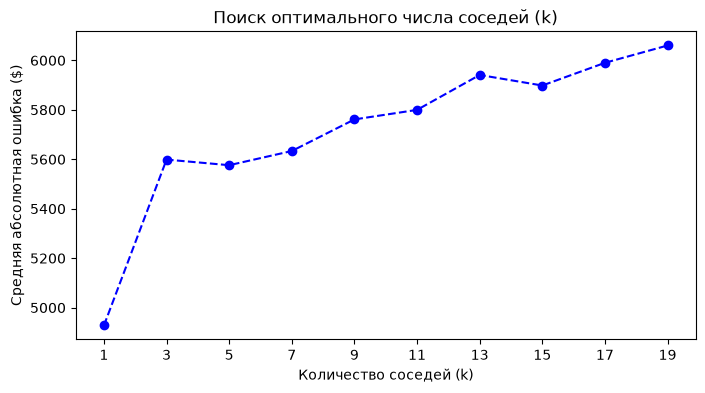

In [4]:
errors = []
k_values = range(1, 20, 2)

for k in k_values:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    errors.append(mean_absolute_error(y_test, y_pred))

plt.figure(figsize=(8,4))
plt.plot(k_values, errors, marker="o", linestyle="dashed", color="blue")
plt.title("Поиск оптимального числа соседей (k)")
plt.xlabel("Количество соседей (k)")
plt.ylabel("Средняя абсолютная ошибка ($)")
plt.xticks(k_values)
plt.show()

In [ ]:
# использовала алгоритм knn для прогнозирования цен автомобилей и проверила разные значения количества соседей k от 1 до 19, для каждого значения рассчитала среднюю абсолютную ошибку (MAE) и построила график, чтобы определить оптимальное количество соседей, при котором ошибка прогноза минимальна   

In [ ]:
# исследование метрик расстояния Минковского

In [7]:
best_k = 5

# Обучаем модель с Евклидовой метрикой (p=2)
knn_euclidean = KNeighborsRegressor(n_neighbors=best_k, p=13)
knn_euclidean.fit(X_train, y_train)
y_pred_euc = knn_euclidean.predict(X_test)

# Обучаем модель с Манхэттенской метрикой (p=1)
knn_manhattan = KNeighborsRegressor(n_neighbors=best_k, p=13)
knn_manhattan.fit(X_train, y_train)
y_pred_man = knn_manhattan.predict(X_test)

print("=== Сравнение метрик расстояния ===")
print(f"Евклидово расстояние (р=2): MAE = ${mean_absolute_error(y_test, y_pred_euc):,.2f} | R2 = {r2_score(y_test, y_pred_euc):,.2f}" )
print(f"Манхэттенское расстояние (р=1): MAE = ${mean_absolute_error(y_test, y_pred_man):,.2f} | R2 = {r2_score(y_test, y_pred_man):,.2f}" )

=== Сравнение метрик расстояния ===
Евклидово расстояние (р=2): MAE = $5,522.16 | R2 = 0.53
Манхэттенское расстояние (р=1): MAE = $5,522.16 | R2 = 0.53


In [ ]:
# обучила две модели KNN с количеством соседей k = 5 и сравнили их качеством по метрикам MAE, с помощью этого точно определила прогнозирование цен автомобилей и определила какая метрика расстояния лучше подходит модели 

In [ ]:
#регрессия Надарая-Ватсона

In [6]:
gamma_values = np.logspace(-2,1 , 30)

best_gamma = 0
best_r2 = -float("inf")
best_mae = float("inf")

for g in gamma_values:
    weights = rbf_kernel(X_test, X_train, gamma=g)
    weights_normalized = weights/ weights.sum(axis=1, keepdims=True)

    y_pred_nw = np.dot(weights_normalized, y_train.values)

    r2 = r2_score(y_test, y_pred_nw)
    mae = mean_absolute_error(y_test, y_pred_nw)

    if r2 > best_r2:
        best_r2 = r2
        best_mae = mae
        best_gamma = g

print("=== Итоги оптимизации ядерной регрессии ===")
print(f"Оптимальный gamma: {best_gamma:.2f}")
print(f"Лучшее R2: {best_r2:.2f}")
print(f"Лучшее MAE: ${best_mae:.2f}")

=== Итоги оптимизации ядерной регрессии ===
Оптимальный gamma: 3.04
Лучшее R2: 0.64
Лучшее MAE: $4085.45


In [ ]:
# применила ядерную регрессию Надарая-Ватсона с RBF-ядром и провела 30 значений параметров gamma. Для каждого значения рассчитала MAE R2, чтобы найти оптимальный параметр, который будет обеспечивать наиболее точное прогназирование цен автомобилей 

In [ ]:
# визуализация 

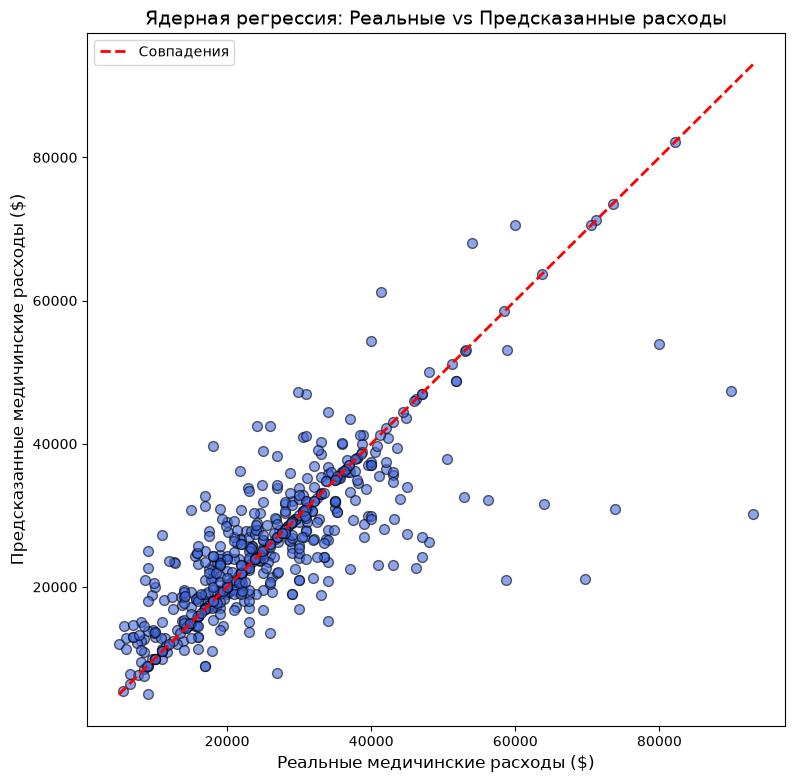

In [8]:
plt.figure(figsize=(9,9))

plt.scatter(y_test, y_pred_nw, alpha=0.6, color="royalblue", edgecolor="k", s=50)

max_val = max(y_test.max(), y_pred_nw.max())
min_val = min(y_test.min(), y_pred_nw.min())

plt.plot(
    [min_val, max_val], [min_val, max_val], "r--", lw=2, label="Совпадения"
)

plt.title("Ядерная регрессия: Реальные vs Предсказанные расходы", fontsize=14)
plt.xlabel("Реальные медичинские расходы ($)", fontsize=12)
plt.ylabel("Предсказанные медичинские расходы ($)", fontsize=12)
plt.legend()
plt.show()

In [ ]:
# построила график сравнения реальных и предсказанных цен автомобилей с помощью ядерной регрессии. чем ближе точки к красной пунктирной линии, тем точнее прогноз модели, это позволяет визуально оценить качество предсказаний и выявить возможное отклонение 